# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance
Dataset: Credit Card Fraud Detection, berisi data transaksi kartu kredit dengan label Class: 0 = transaksi normal, 1 = transaksi penipuan (fraud).

Link: https://www.kaggle.com/mlg-ulb/creditcardfraud


## 1. Unduh dan Import Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

In [2]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. EDA

In [3]:
print('Shape dataset:', df.shape)
print('Jumlah baris  :', df.shape[0])
print('Jumlah kolom  :', df.shape[1])

Shape dataset: (284807, 31)
Jumlah baris  : 284807
Jumlah kolom  : 31


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [5]:
df[['Time', 'Amount', 'Class']].describe()

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


In [6]:
# Pemeriksaan missing values
missing = df.isnull().sum()
print('Total missing values:', missing.sum())
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [7]:
# Pemeriksaan data duplikat
n_dup = df.duplicated().sum()
print('Jumlah baris duplikat:', n_dup)
print('Distribusi kelas pada baris duplikat:')
print(df[df.duplicated()]['Class'].value_counts())

Jumlah baris duplikat: 1081
Distribusi kelas pada baris duplikat:
Class
0    1062
1      19
Name: count, dtype: int64


In [8]:
# Simulasi: jika duplikat TIDAK dihapus, berapa baris data uji yang punya salinan persis di data latih?
X_raw, y_raw = df.drop(columns='Class'), df['Class']
X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=RANDOM_STATE
)
train_raw = X_tr_raw.assign(Class=y_tr_raw).drop_duplicates()
test_raw = X_te_raw.assign(Class=y_te_raw)

bocor = test_raw.merge(train_raw, how='inner')   # baris data uji yang identik dengan baris di data latih
print('Baris data uji yang punya salinan persis di data latih:', len(bocor))
print(f"Fraud di data uji yang ikut bocor: {bocor['Class'].sum()} dari {y_te_raw.sum()} fraud "
      f"({bocor['Class'].sum() / y_te_raw.sum() * 100:.1f}%)")

Baris data uji yang punya salinan persis di data latih: 344
Fraud di data uji yang ikut bocor: 8 dari 98 fraud (8.2%)


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape setelah menghapus duplikat:', df.shape)

Shape setelah menghapus duplikat: (283726, 31)


In [10]:
# Distribusi kelas
class_count = df['Class'].value_counts().sort_index()
class_pct = df['Class'].value_counts(normalize=True).sort_index() * 100

class_dist = pd.DataFrame({'Jumlah': class_count, 'Persentase (%)': class_pct.round(4)})
class_dist.index = ['0 - Normal', '1 - Fraud']
print(class_dist)
print(f"\nRasio normal : fraud = {class_count[0] / class_count[1]:.0f} : 1")

            Jumlah  Persentase (%)
0 - Normal  283253         99.8333
1 - Fraud      473          0.1667

Rasio normal : fraud = 599 : 1


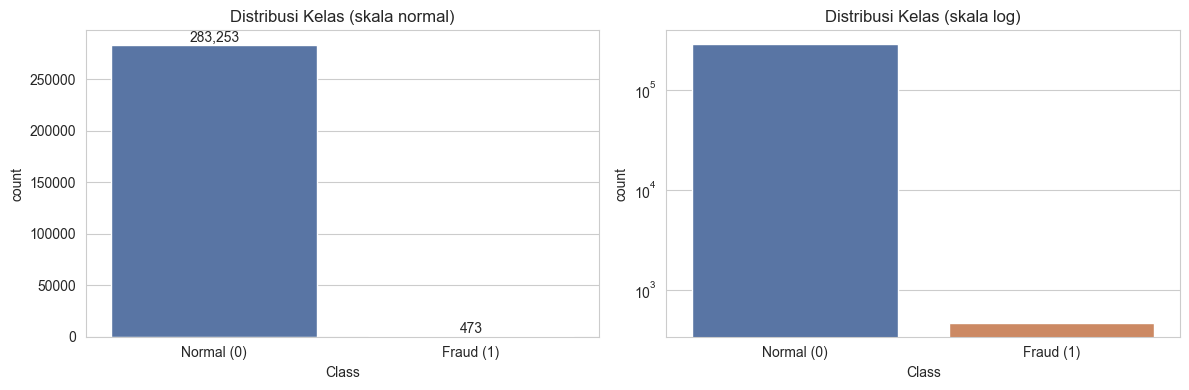

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='Class', data=df, ax=ax[0], palette=['#4C72B0', '#DD8452'])
ax[0].set_title('Distribusi Kelas (skala normal)')
ax[0].set_xticklabels(['Normal (0)', 'Fraud (1)'])
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom')

sns.countplot(x='Class', data=df, ax=ax[1], palette=['#4C72B0', '#DD8452'])
ax[1].set_yscale('log')
ax[1].set_title('Distribusi Kelas (skala log)')
ax[1].set_xticklabels(['Normal (0)', 'Fraud (1)'])

plt.tight_layout()
plt.show()

## 3. Praproses Data

In [12]:
X = df.drop(columns='Class')
y = df['Class']
print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (283726, 30)
Shape y: (283726,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('\nDistribusi kelas data latih (%):')
print((y_train.value_counts(normalize=True) * 100).round(4))
print('\nDistribusi kelas data uji (%):')
print((y_test.value_counts(normalize=True) * 100).round(4))

Data latih: (226980, 30) | Data uji: (56746, 30)

Distribusi kelas data latih (%):
Class
0    99.8335
1     0.1665
Name: proportion, dtype: float64

Distribusi kelas data uji (%):
Class
0    99.8326
1     0.1674
Name: proportion, dtype: float64


In [14]:
scale_cols = ['Time', 'Amount']
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit hanya di data latih
X_test[scale_cols] = scaler.transform(X_test[scale_cols])         # data uji hanya di-transform

X_train[scale_cols].describe().round(3)

,Time,Amount
count,226980.000,226980.000
mean,-0.000,0.000
std,1.000,1.000
min,-1.998,-0.360
25%,-0.856,-0.336
50%,-0.212,-0.270
75%,0.936,-0.043
max,1.640,79.621


### 3.1 Penanganan Class Imbalance dengan SMOTE

In [15]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

dist_smote = pd.DataFrame({
    'Sebelum SMOTE': y_train.value_counts().sort_index(),
    'Sesudah SMOTE': y_train_smote.value_counts().sort_index()
})
dist_smote.index = ['0 - Normal', '1 - Fraud']
print(dist_smote)
print('\nShape data latih sebelum SMOTE:', X_train.shape)
print('Shape data latih sesudah SMOTE:', X_train_smote.shape)

            Sebelum SMOTE  Sesudah SMOTE
0 - Normal         226602         226602
1 - Fraud             378         226602

Shape data latih sebelum SMOTE: (226980, 30)
Shape data latih sesudah SMOTE: (453204, 30)


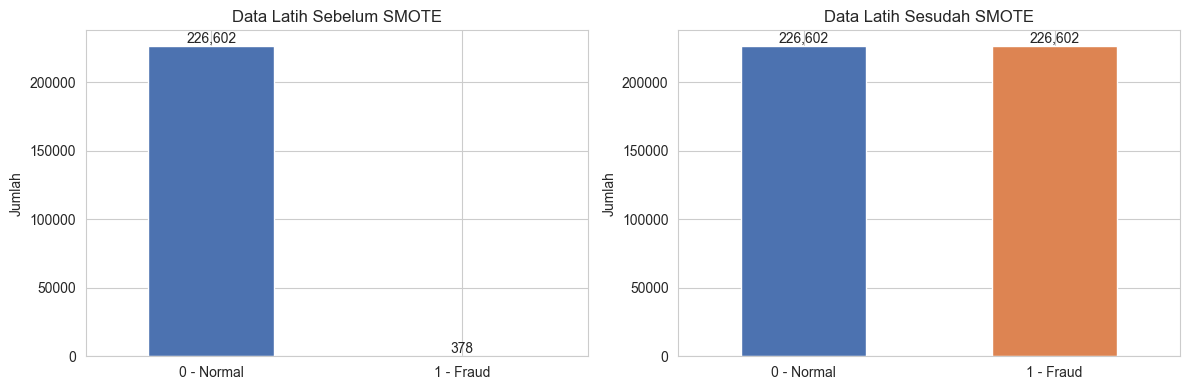

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dist_smote['Sebelum SMOTE'].plot(kind='bar', ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Data Latih Sebelum SMOTE')
dist_smote['Sesudah SMOTE'].plot(kind='bar', ax=ax[1], color=['#4C72B0', '#DD8452'])
ax[1].set_title('Data Latih Sesudah SMOTE')
for a in ax:
    a.set_ylabel('Jumlah')
    a.tick_params(axis='x', rotation=0)
    for p in a.patches:
        a.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom')
plt.tight_layout()
plt.show()

Setelah SMOTE, jumlah kelas fraud pada data latih menjadi sama dengan kelas normal (rasio 1:1)

### 3.2 Penanganan Class Imbalance dengan Undersampling

In [17]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

dist_resample = pd.DataFrame({
    'Data latih asli': y_train.value_counts().sort_index(),
    'Sesudah SMOTE': y_train_smote.value_counts().sort_index(),
    'Sesudah Undersampling': y_train_rus.value_counts().sort_index()
})
dist_resample.index = ['0 - Normal', '1 - Fraud']
print(dist_resample)
print('\nShape data latih sesudah undersampling:', X_train_rus.shape)
print(f'Data normal yang dibuang: {len(y_train) - len(y_train_rus):,} baris '
      f'({(len(y_train) - len(y_train_rus)) / (y_train == 0).sum() * 100:.2f}% dari data normal)')

            Data latih asli  Sesudah SMOTE  Sesudah Undersampling
0 - Normal           226602         226602                    378
1 - Fraud               378         226602                    378

Shape data latih sesudah undersampling: (756, 30)
Data normal yang dibuang: 226,224 baris (99.83% dari data normal)


## 4. Membangun Model Klasifikasi

- Random Forest
- XGBoost

Setiap model dibandingkan tanpa dan dengan penanganan class imbalance sehingga totalnya ada 6 skenario

| Strategi | Random Forest | XGBoost |
|---|---|---|
| Tanpa penanganan (baseline) | Skenario 1 | Skenario 4 |
| Oversampling: SMOTE | Skenario 2 | Skenario 5 |
| Undersampling: Random Undersampling | Skenario 3 | Skenario 6 |

### 4.1 Random Forest

In [18]:
rf_params = {'n_estimators': 100, 'random_state': RANDOM_STATE, 'n_jobs': -1}
rf_params

{'n_estimators': 100, 'random_state': 42, 'n_jobs': -1}

#### Skenario 1: Random Forest Baseline (tanpa penanganan imbalance)

In [19]:
%%time
rf_baseline = RandomForestClassifier(**rf_params)
rf_baseline.fit(X_train, y_train)

y_pred_base = rf_baseline.predict(X_test)
y_proba_base = rf_baseline.predict_proba(X_test)[:, 1]   # probabilitas kelas fraud

CPU times: total: 5min 13s
Wall time: 1min 37s


#### Skenario 2: Random Forest + SMOTE

In [20]:
%%time
rf_smote = RandomForestClassifier(**rf_params)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test)
y_proba_smote = rf_smote.predict_proba(X_test)[:, 1]

CPU times: total: 9min 46s
Wall time: 6min 30s


#### Skenario 3: Random Forest + Undersampling

In [21]:
%%time
rf_rus = RandomForestClassifier(**rf_params)
rf_rus.fit(X_train_rus, y_train_rus)

y_pred_rf_rus = rf_rus.predict(X_test)
y_proba_rf_rus = rf_rus.predict_proba(X_test)[:, 1]

CPU times: total: 1.47 s
Wall time: 699 ms


### 3.2 XGBoost

In [22]:
xgb_params = {
    'n_estimators': 300,
    'learning_rate': 0.1,
    'max_depth': 6,
    'tree_method': 'hist',
    'eval_metric': 'logloss',
    'random_state': RANDOM_STATE,
    'n_jobs': -1
}
xgb_params

{'n_estimators': 300,
 'learning_rate': 0.1,
 'max_depth': 6,
 'tree_method': 'hist',
 'eval_metric': 'logloss',
 'random_state': 42,
 'n_jobs': -1}

#### Skenario 4: XGBoost Baseline (tanpa penanganan imbalance)

In [23]:
%%time
xgb_baseline = XGBClassifier(**xgb_params)
xgb_baseline.fit(X_train, y_train)
y_pred_xgb_base = xgb_baseline.predict(X_test)
y_proba_xgb_base = xgb_baseline.predict_proba(X_test)[:, 1]

CPU times: total: 29.1 s
Wall time: 11.5 s


#### Skenario 5: XGBoost + SMOTE

In [24]:
%%time
xgb_smote = XGBClassifier(**xgb_params)
xgb_smote.fit(X_train_smote, y_train_smote)
y_pred_xgb_smote = xgb_smote.predict(X_test)
y_proba_xgb_smote = xgb_smote.predict_proba(X_test)[:, 1]

CPU times: total: 53.7 s
Wall time: 19.4 s


#### Skenario 6: XGBoost + Undersampling

In [25]:
%%time
xgb_rus = XGBClassifier(**xgb_params)
xgb_rus.fit(X_train_rus, y_train_rus)
y_pred_xgb_rus = xgb_rus.predict(X_test)
y_proba_xgb_rus = xgb_rus.predict_proba(X_test)[:, 1]

CPU times: total: 2.97 s
Wall time: 1.34 s


## 5. Evaluasi Model

In [26]:
hasil_prediksi = {
    'RF Baseline': (y_pred_base, y_proba_base),
    'RF + SMOTE': (y_pred_smote, y_proba_smote),
    'RF + Undersampling': (y_pred_rf_rus, y_proba_rf_rus),
    'XGB Baseline': (y_pred_xgb_base, y_proba_xgb_base),
    'XGB + SMOTE': (y_pred_xgb_smote, y_proba_xgb_smote),
    'XGB + Undersampling': (y_pred_xgb_rus, y_proba_xgb_rus),
}

nama_rf = ['RF Baseline', 'RF + SMOTE', 'RF + Undersampling']
nama_xgb = ['XGB Baseline', 'XGB + SMOTE', 'XGB + Undersampling']
strategi = ['Baseline', 'SMOTE', 'Undersampling']

In [27]:
for nama in nama_rf:
    y_pred, _ = hasil_prediksi[nama]
    print(f'{nama}')
    print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Fraud (1)'], digits=4))

RF Baseline
              precision    recall  f1-score   support

  Normal (0)     0.9995    1.0000    0.9998     56651
   Fraud (1)     0.9718    0.7263    0.8313        95

    accuracy                         0.9995     56746
   macro avg     0.9857    0.8631    0.9155     56746
weighted avg     0.9995    0.9995    0.9995     56746

RF + SMOTE
              precision    recall  f1-score   support

  Normal (0)     0.9996    0.9999    0.9997     56651
   Fraud (1)     0.9114    0.7579    0.8276        95

    accuracy                         0.9995     56746
   macro avg     0.9555    0.8789    0.9137     56746
weighted avg     0.9994    0.9995    0.9994     56746

RF + Undersampling
              precision    recall  f1-score   support

  Normal (0)     0.9998    0.9842    0.9919     56651
   Fraud (1)     0.0848    0.8737    0.1546        95

    accuracy                         0.9840     56746
   macro avg     0.5423    0.9289    0.5732     56746
weighted avg     0.9983    0.984

In [28]:
for nama in nama_xgb:
    y_pred, _ = hasil_prediksi[nama]
    print(f'{nama}')
    print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Fraud (1)'], digits=4))

XGB Baseline
              precision    recall  f1-score   support

  Normal (0)     0.9995    0.9999    0.9997     56651
   Fraud (1)     0.9452    0.7263    0.8214        95

    accuracy                         0.9995     56746
   macro avg     0.9724    0.8631    0.9106     56746
weighted avg     0.9995    0.9995    0.9994     56746

XGB + SMOTE
              precision    recall  f1-score   support

  Normal (0)     0.9996    0.9995    0.9996     56651
   Fraud (1)     0.7212    0.7895    0.7538        95

    accuracy                         0.9991     56746
   macro avg     0.8604    0.8945    0.8767     56746
weighted avg     0.9992    0.9991    0.9992     56746

XGB + Undersampling
              precision    recall  f1-score   support

  Normal (0)     0.9998    0.9715    0.9854     56651
   Fraud (1)     0.0489    0.8737    0.0926        95

    accuracy                         0.9713     56746
   macro avg     0.5243    0.9226    0.5390     56746
weighted avg     0.9982    0.

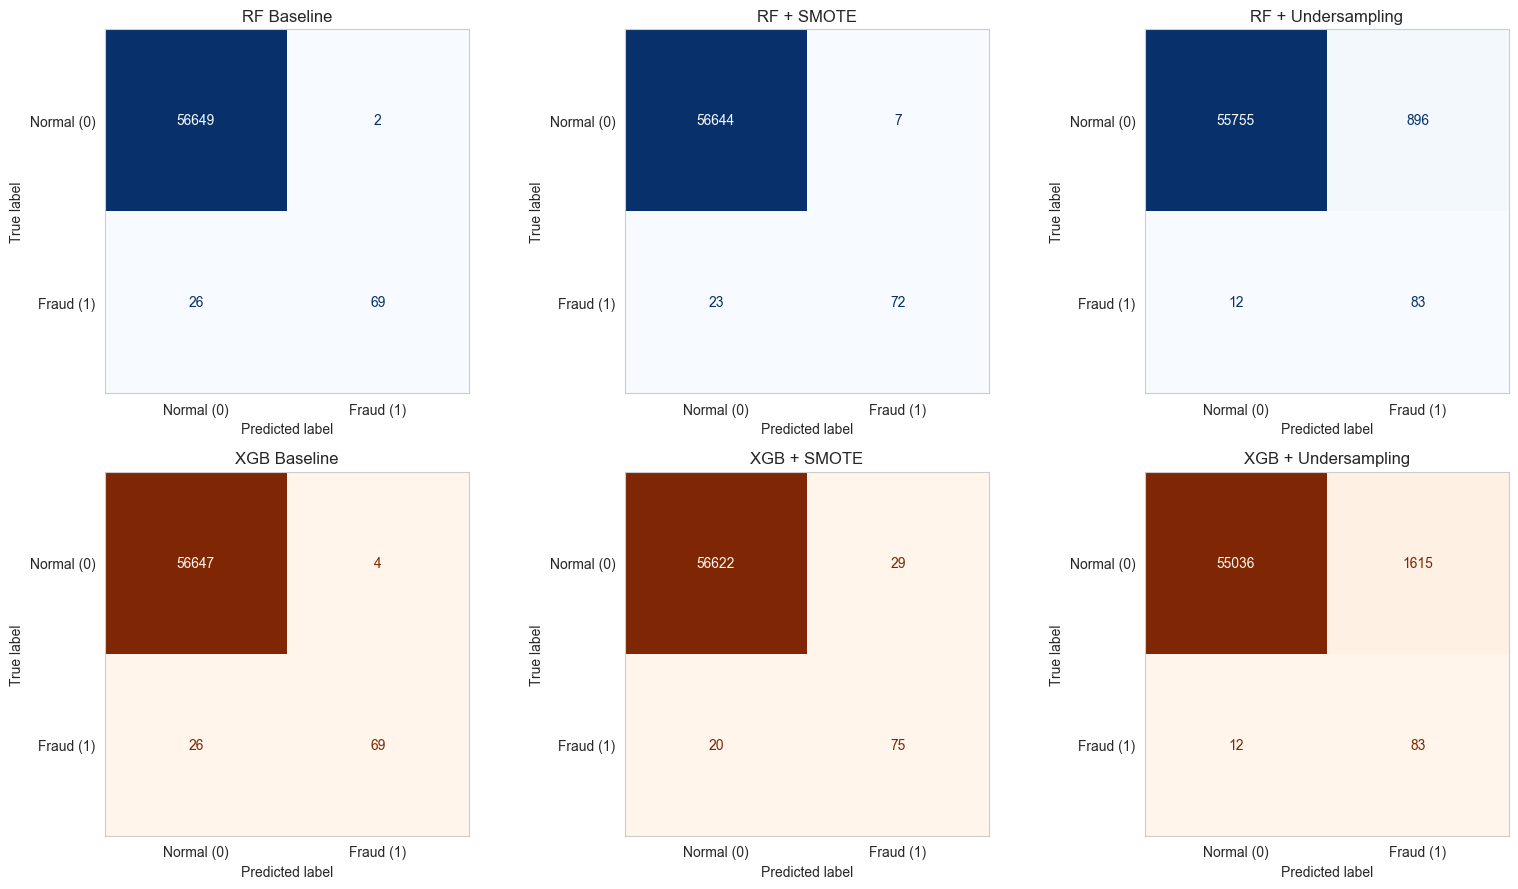

RF Baseline          -> TN=56649, FP=2, FN=26, TP=69
RF + SMOTE           -> TN=56644, FP=7, FN=23, TP=72
RF + Undersampling   -> TN=55755, FP=896, FN=12, TP=83
XGB Baseline         -> TN=56647, FP=4, FN=26, TP=69
XGB + SMOTE          -> TN=56622, FP=29, FN=20, TP=75
XGB + Undersampling  -> TN=55036, FP=1615, FN=12, TP=83


In [29]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for baris, (daftar_nama, cmap) in enumerate([(nama_rf, 'Blues'), (nama_xgb, 'Oranges')]):
    for kolom, nama in enumerate(daftar_nama):
        y_pred, _ = hasil_prediksi[nama]
        ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Normal (0)', 'Fraud (1)']).plot(
            ax=ax[baris, kolom], cmap=cmap, values_format='d', colorbar=False)
        ax[baris, kolom].set_title(nama)
        ax[baris, kolom].grid(False)
plt.tight_layout()
plt.show()

for nama in hasil_prediksi:
    tn, fp, fn, tp = confusion_matrix(y_test, hasil_prediksi[nama][0]).ravel()
    print(f'{nama:20s} -> TN={tn}, FP={fp}, FN={fn}, TP={tp}')

### 5.3 Tabel Perbandingan Performa

In [30]:
def hitung_metrik(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Fraud)': precision_score(y_true, y_pred, pos_label=1),
        'Recall (Fraud)': recall_score(y_true, y_pred, pos_label=1),
        'F1-Score (Fraud)': f1_score(y_true, y_pred, pos_label=1),
        'AUC-ROC': roc_auc_score(y_true, y_proba),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    }

hasil = pd.DataFrame({
    nama: hitung_metrik(y_test, y_pred, y_proba)
    for nama, (y_pred, y_proba) in hasil_prediksi.items()
}).T

metrik_utama = ['Accuracy', 'Precision (Fraud)', 'Recall (Fraud)', 'F1-Score (Fraud)', 'AUC-ROC']
hasil[metrik_utama] = hasil[metrik_utama].astype(float).round(4)
hasil[['TP', 'FP', 'FN', 'TN']] = hasil[['TP', 'FP', 'FN', 'TN']].astype(int)
hasil

,Accuracy,Precision (Fraud),Recall (Fraud),F1-Score (Fraud),AUC-ROC,TP,FP,FN,TN
RF Baseline,0.9995,0.9718,0.7263,0.8313,0.9239,69,2,26,56649
RF + SMOTE,0.9995,0.9114,0.7579,0.8276,0.9662,72,7,23,56644
RF + Undersampling,0.9840,0.0848,0.8737,0.1546,0.9767,83,896,12,55755
XGB Baseline,0.9995,0.9452,0.7263,0.8214,0.9753,69,4,26,56647
XGB + SMOTE,0.9991,0.7212,0.7895,0.7538,0.9685,75,29,20,56622
XGB + Undersampling,0.9713,0.0489,0.8737,0.0926,0.9778,83,1615,12,55036


In [31]:
tabel_f1 = pd.DataFrame({
    'Random Forest': hasil.loc[nama_rf, 'F1-Score (Fraud)'].values,
    'XGBoost': hasil.loc[nama_xgb, 'F1-Score (Fraud)'].values
}, index=strategi)
tabel_f1.index.name = 'Strategi'
tabel_f1

,Random Forest,XGBoost
Strategi,,
Baseline,0.8313,0.8214
SMOTE,0.8276,0.7538
Undersampling,0.1546,0.0926


In [32]:
akurasi_dummy = (y_test == 0).mean()
print(f'Accuracy model yang selalu menebak normal: {akurasi_dummy:.4f} (fraud terdeteksi: 0 dari {y_test.sum()})')

hasil[['Accuracy', 'Recall (Fraud)', 'Precision (Fraud)', 'TP', 'FP', 'FN']]

Accuracy model yang selalu menebak normal: 0.9983 (fraud terdeteksi: 0 dari 95)


,Accuracy,Recall (Fraud),Precision (Fraud),TP,FP,FN
RF Baseline,0.9995,0.7263,0.9718,69,2,26
RF + SMOTE,0.9995,0.7579,0.9114,72,7,23
RF + Undersampling,0.9840,0.8737,0.0848,83,896,12
XGB Baseline,0.9995,0.7263,0.9452,69,4,26
XGB + SMOTE,0.9991,0.7895,0.7212,75,29,20
XGB + Undersampling,0.9713,0.8737,0.0489,83,1615,12


### 5.5 Visualisasi Perbandingan Metrik

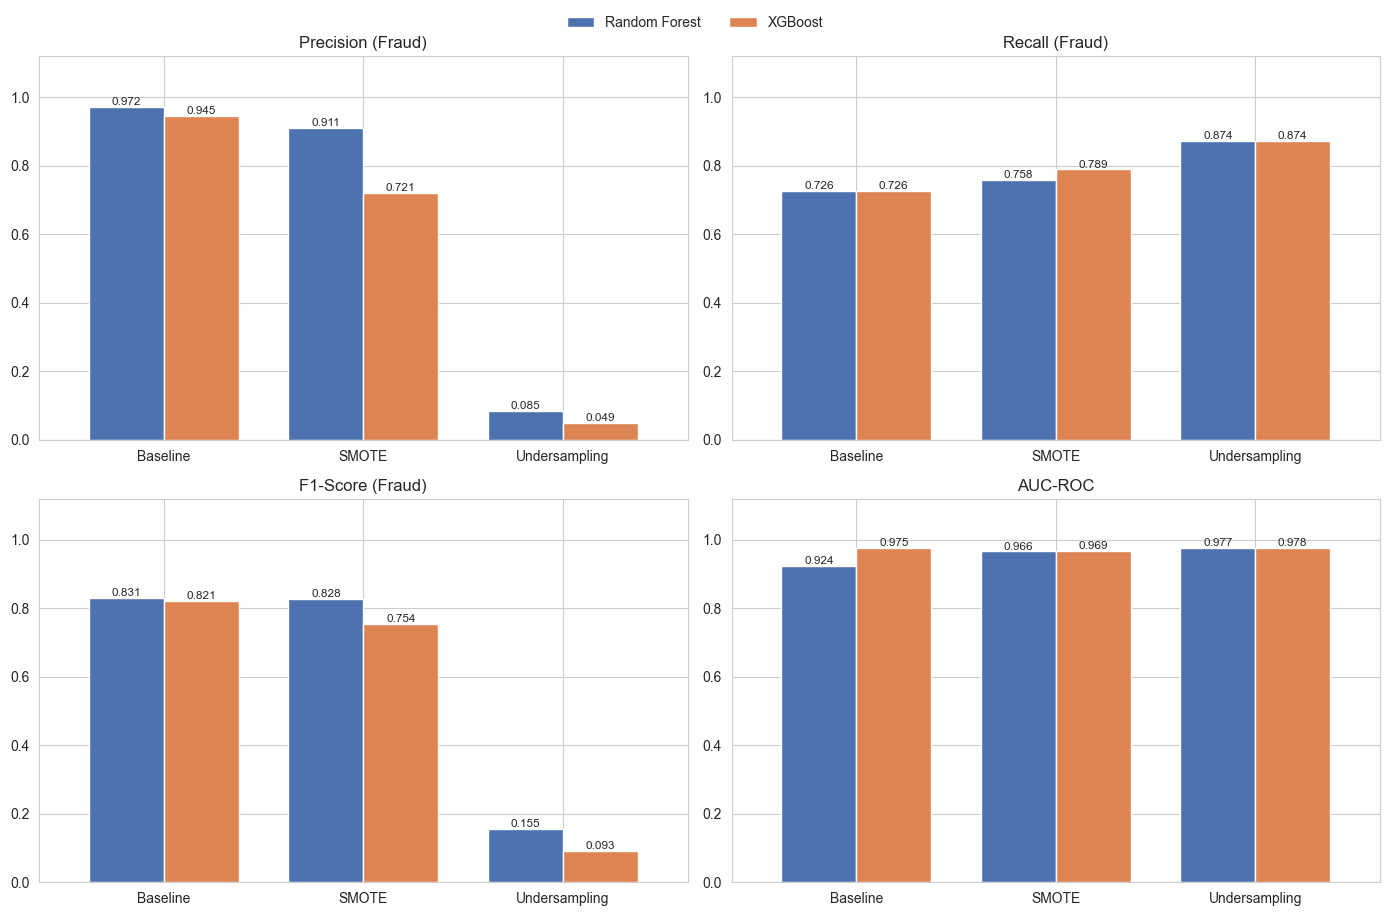

In [33]:
metrik_plot = ['Precision (Fraud)', 'Recall (Fraud)', 'F1-Score (Fraud)', 'AUC-ROC']
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, metrik in zip(ax.ravel(), metrik_plot):
    df_plot = pd.DataFrame({
        'Random Forest': hasil.loc[nama_rf, metrik].values,
        'XGBoost': hasil.loc[nama_xgb, metrik].values
    }, index=strategi)
    df_plot.plot(kind='bar', ax=a, color=['#4C72B0', '#DD8452'], width=0.75, legend=False)
    a.set_title(metrik)
    a.set_ylim(0, 1.12)
    a.tick_params(axis='x', rotation=0)
    for p in a.patches:
        a.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom', fontsize=8.5)
handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

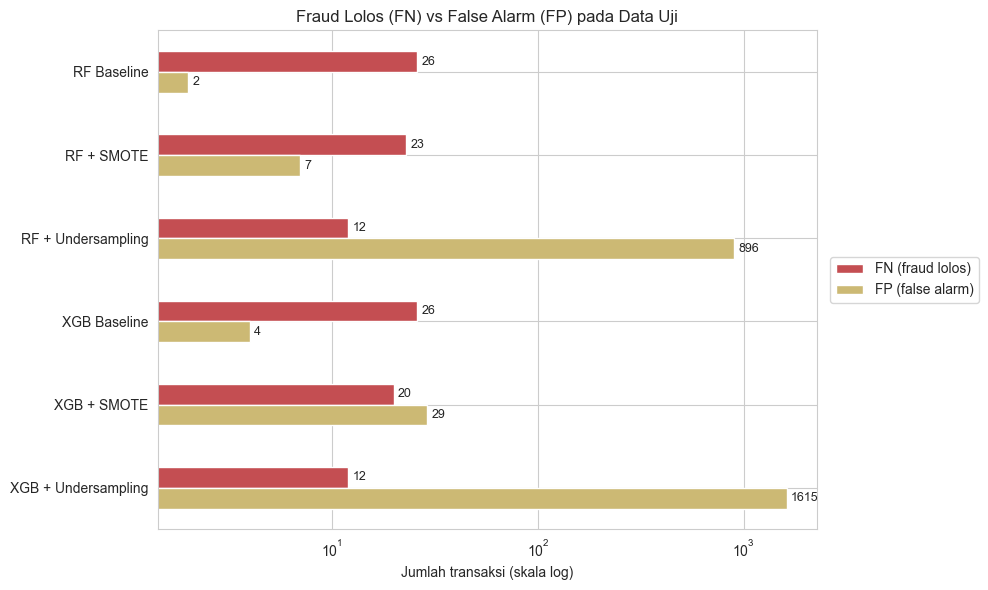

In [34]:
# Jumlah fraud yang lolos (FN) vs false alarm (FP) per skenario (sumbu-x skala log karena rentang FP sangat lebar)
ax = hasil[['FN', 'FP']].plot(kind='barh', figsize=(10, 6), color=['#C44E52', '#CCB974'])
ax.set_title('Fraud Lolos (FN) vs False Alarm (FP) pada Data Uji')
ax.set_xlabel('Jumlah transaksi (skala log)')
ax.set_xscale('log')
ax.invert_yaxis()
ax.legend(['FN (fraud lolos)', 'FP (false alarm)'], loc='center left', bbox_to_anchor=(1.01, 0.5))
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}', (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9, xytext=(3, 0), textcoords='offset points')
plt.tight_layout()
plt.show()

### 5.6 Kurva ROC

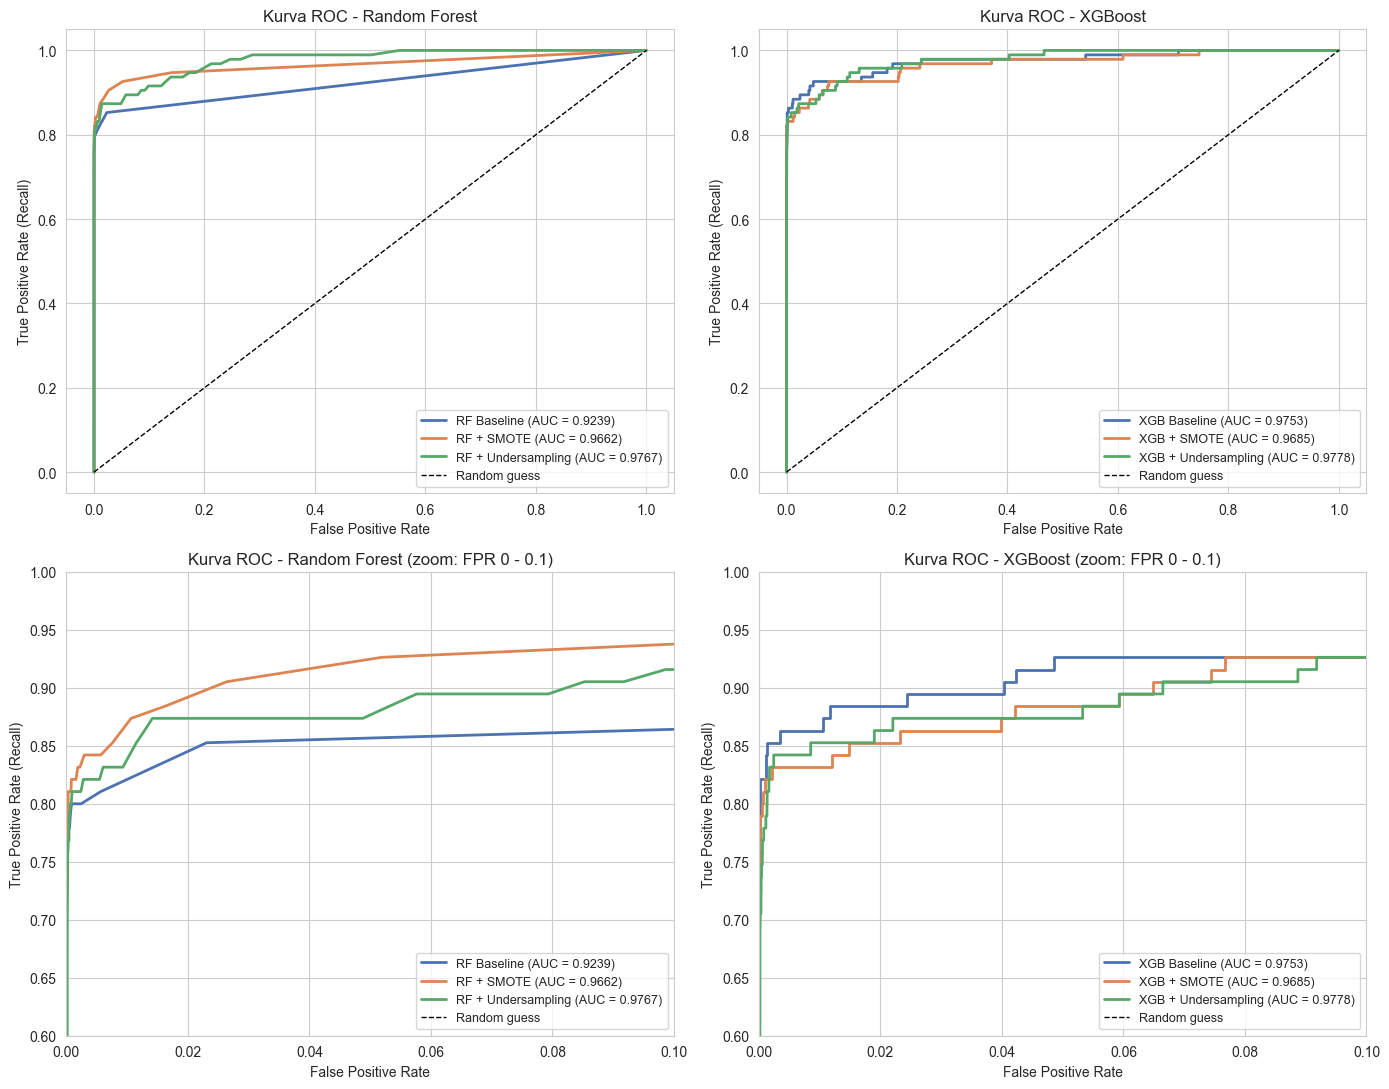

In [35]:
warna_strategi = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
for kolom, (judul, daftar_nama) in enumerate([('Random Forest', nama_rf), ('XGBoost', nama_xgb)]):
    for nama, warna in zip(daftar_nama, warna_strategi):
        proba = hasil_prediksi[nama][1]
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc = roc_auc_score(y_test, proba)
        for baris in [0, 1]:
            ax[baris, kolom].plot(fpr, tpr, color=warna, lw=2, label=f'{nama} (AUC = {auc:.4f})')
    for baris in [0, 1]:
        a = ax[baris, kolom]
        a.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
        a.set_xlabel('False Positive Rate')
        a.set_ylabel('True Positive Rate (Recall)')
        a.legend(loc='lower right', fontsize=9)
    ax[0, kolom].set_title(f'Kurva ROC - {judul}')
    ax[1, kolom].set_xlim(0, 0.1)
    ax[1, kolom].set_ylim(0.6, 1.0)
    ax[1, kolom].set_title(f'Kurva ROC - {judul} (zoom: FPR 0 - 0.1)')
plt.tight_layout()
plt.show()

## 6. Kesimpulan

### Ringkasan Hasil (data uji: 56.746 transaksi, 95 di antaranya fraud)

| Model | Strategi | Precision (Fraud) | Recall (Fraud) | F1 (Fraud) | AUC-ROC | TP | FP | FN |
|---|---|---|---|---|---|---|---|---|
| Random Forest | Baseline | **0,9718** | 0,7263 | **0,8313** | 0,9239 | 69 | **2** | 26 |
| Random Forest | SMOTE | 0,9114 | 0,7579 | 0,8276 | 0,9662 | 72 | 7 | 23 |
| Random Forest | Undersampling | 0,0848 | **0,8737** | 0,1546 | **0,9767** | **83** | 896 | **12** |
| XGBoost | Baseline | **0,9452** | 0,7263 | **0,8214** | 0,9753 | 69 | **4** | 26 |
| XGBoost | SMOTE | 0,7212 | 0,7895 | 0,7538 | 0,9685 | 75 | 29 | 20 |
| XGBoost | Undersampling | 0,0489 | **0,8737** | 0,0926 | **0,9778** | **83** | 1.615 | **12** |

Berdasarkan hasil eksperimen, **Random Forest + SMOTE** adalah pilihan yang paling seimbang:
1. Menangkap lebih banyak fraud daripada kedua baseline (72 vs 69), dengan false alarm yang tetap sangat rendah (7 dari 56.651 transaksi normal).
2. F1-score hampir setara dengan skor tertinggi (0,8276 vs 0,8313), sementara AUC-ROC jauh lebih baik daripada RF Baseline.
3. Lebih seimbang daripada XGB + SMOTE (29 false alarm) dan kedua skenario undersampling (ratusan hingga ribuan false alarm).

Ensemble method sudah bekerja baik untuk dataset ini bahkan tanpa penanganan imbalance. SMOTE membantu menaikkan recall dengan penurunan precision yang moderat, dan paling cocok dipasangkan dengan Random Forest. Undersampling tidak cocok untuk dataset ini karena membuang hampir seluruh data normal. Pemilihan model akhir tetap perlu mempertimbangkan perbandingan biaya fraud yang lolos (FN) dengan biaya false alarm (FP). Sebagai pengembangan, teknik lain seperti cost-sensitive learning atau penyesuaian threshold dapat dicoba untuk memperbaiki keseimbangan precision dan recall.